<a href="https://colab.research.google.com/github/Sharu-052897/deep-learning/blob/main/RNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, GRU, Dense, Dropout
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator

print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)

All libraries imported successfully!
TensorFlow version: 2.21.0


In [2]:
np.random.seed(42)

days = 1000

temperature = 25 + 8 * np.sin(np.arange(days) * 2 * np.pi / 365) + np.random.normal(0, 1, days)

humidity = 60 + 15 * np.sin(np.arange(days) * 2 * np.pi / 365 + 1) + np.random.normal(0, 2, days)

pressure = 1013 + np.random.normal(0, 3, days)

wind_speed = 10 + np.random.normal(0, 2, days)

data = pd.DataFrame({
    'Temperature': temperature,
    'Humidity': humidity,
    'Pressure': pressure,
    'WindSpeed': wind_speed
})

print(data.head())
print("\nDataset shape:", data.shape)

   Temperature   Humidity     Pressure  WindSpeed
0    25.496714  75.420776  1010.974465   6.184385
1    24.999443  74.608968  1012.566444   8.279230
2    25.923061  73.012817  1010.622740   9.172789
3    26.935987  71.729717  1012.076115  13.775375
4    25.316266  74.546213  1007.319156  11.113106

Dataset shape: (1000, 4)


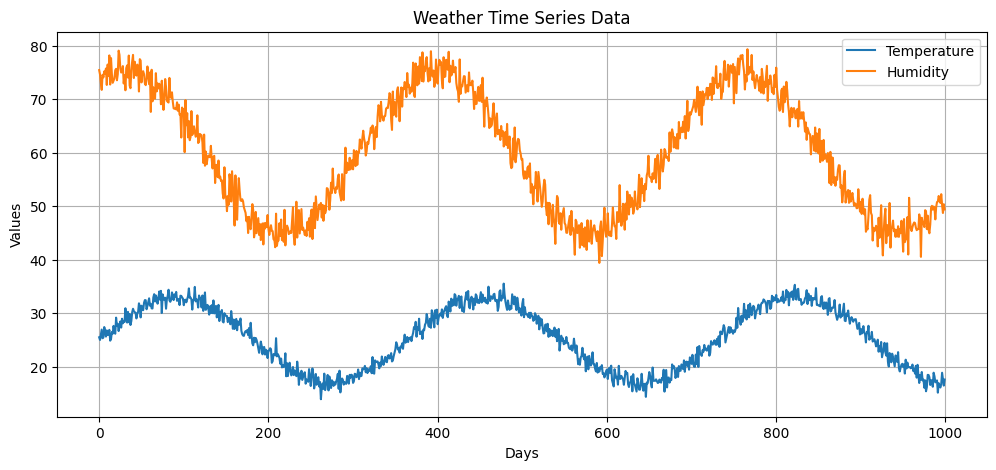

In [3]:
plt.figure(figsize=(12, 5))

plt.plot(data['Temperature'], label='Temperature')
plt.plot(data['Humidity'], label='Humidity')

plt.title("Weather Time Series Data")
plt.xlabel("Days")
plt.ylabel("Values")
plt.legend()
plt.grid()

plt.show()

In [4]:
scaler = MinMaxScaler()

split = int(len(data) * 0.8)

scaler.fit(data.iloc[:split])

scaled_data = scaler.transform(data)

print("Data normalization completed!")
print("Training samples:", split)
print("Testing samples:", len(data) - split)

Data normalization completed!
Training samples: 800
Testing samples: 200


In [5]:
LOOKBACK = 14
BATCH_SIZE = 32

train_data = scaled_data[:split]

train_generator = TimeseriesGenerator(
    train_data,
    train_data[:, 0],
    length=LOOKBACK,
    batch_size=BATCH_SIZE
)

test_generator = TimeseriesGenerator(
    scaled_data,
    scaled_data[:, 0],
    length=LOOKBACK,
    batch_size=BATCH_SIZE,
    start_index=split - 1
)

print("Time series sequences generated successfully!")
print("Training batches:", len(train_generator))
print("Testing batches:", len(test_generator))

x, y = train_generator[0]

print("Input shape:", x.shape)
print("Output shape:", y.shape)

Time series sequences generated successfully!
Training batches: 25
Testing batches: 6
Input shape: (32, 14, 4)
Output shape: (32,)


In [6]:
simple_rnn = Sequential([
    tf.keras.Input(shape=(LOOKBACK, 4)),

    SimpleRNN(64, activation='tanh'),

    Dropout(0.2),

    Dense(32, activation='relu'),

    Dense(1)
])

simple_rnn.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

simple_rnn.summary()

print("SimpleRNN model created successfully!")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         4,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,529 (25.50 KB)

 Trainable params: 6,529 (25.50 KB)

 Non-trainable params: 0 (0.00 B)

SimpleRNN model created successfully!


In [7]:
rnn_history = simple_rnn.fit(
    train_generator,
    validation_data=test_generator,
    epochs=10,
    verbose=1
)

Epoch 1/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 7s 162ms/step - loss: 0.1034 - mae: 0.2379 - val_loss: 0.0076 - val_mae: 0.0723
Epoch 2/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0241 - mae: 0.1241 - val_loss: 0.0074 - val_mae: 0.0682
Epoch 3/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0180 - mae: 0.1067 - val_loss: 0.0116 - val_mae: 0.0872
Epoch 4/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0172 - mae: 0.1055 - val_loss: 0.0095 - val_mae: 0.0799
Epoch 5/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0141 - mae: 0.0943 - val_loss: 0.0063 - val_mae: 0.0645
Epoch 6/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0134 - mae: 0.0907 - val_loss: 0.0049 - val_mae: 0.0551
Epoch 7/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0108 - mae: 0.0828 - val_loss: 0.0042 - val_mae: 0.0525
Epoch 8/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0101 - mae: 0.0794 - val_loss: 0.0049 - val_mae: 0.0564
Epoch 9/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0113 - mae

In [8]:
gru_model = Sequential([
    tf.keras.Input(shape=(LOOKBACK, 4)),

    GRU(64, activation='tanh'),

    Dropout(0.2),

    Dense(32, activation='relu'),

    Dense(1)
])

gru_model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

gru_model.summary()

print("GRU model created successfully!")

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 64)             │        13,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,553 (60.75 KB)

 Trainable params: 15,553 (60.75 KB)

 Non-trainable params: 0 (0.00 B)

GRU model created successfully!


In [9]:
gru_history = gru_model.fit(
    train_generator,
    validation_data=test_generator,
    epochs=10,
    verbose=1
)

Epoch 1/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - loss: 0.1719 - mae: 0.3396 - val_loss: 0.0225 - val_mae: 0.1270
Epoch 2/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0329 - mae: 0.1496 - val_loss: 0.0112 - val_mae: 0.0863
Epoch 3/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0181 - mae: 0.1121 - val_loss: 0.0050 - val_mae: 0.0556
Epoch 4/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0108 - mae: 0.0844 - val_loss: 0.0030 - val_mae: 0.0437
Epoch 5/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0068 - mae: 0.0638 - val_loss: 0.0031 - val_mae: 0.0443
Epoch 6/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0061 - mae: 0.0616 - val_loss: 0.0023 - val_mae: 0.0382
Epoch 7/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0060 - mae: 0.0607 - val_loss: 0.0030 - val_mae: 0.0427
Epoch 8/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0057 - mae: 0.0596 - val_loss: 0.0025 - val_mae: 0.0406
Epoch 9/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0058 - mae:

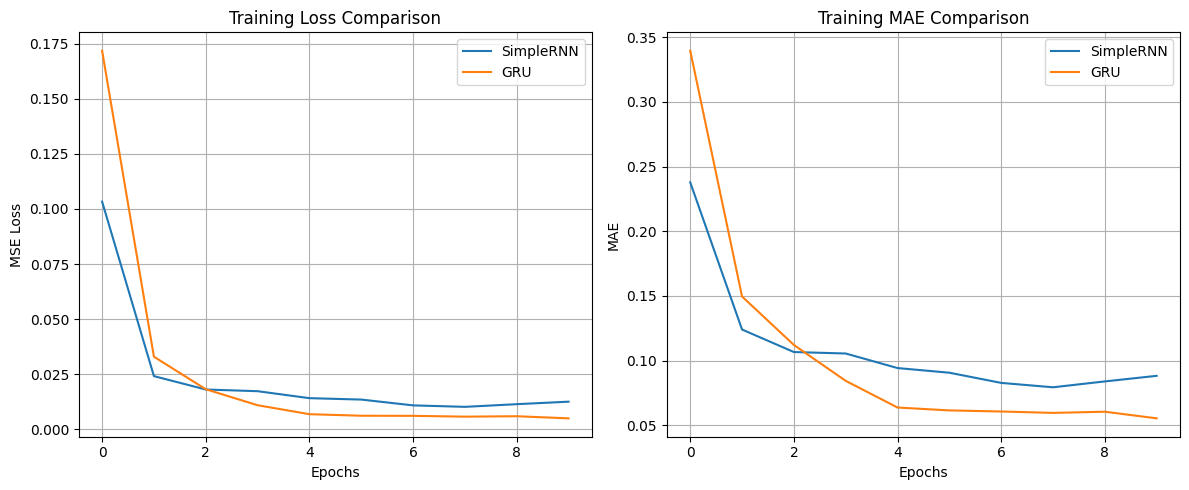

In [10]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(rnn_history.history['loss'], label='SimpleRNN')
plt.plot(gru_history.history['loss'], label='GRU')

plt.title("Training Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)

plt.plot(rnn_history.history['mae'], label='SimpleRNN')
plt.plot(gru_history.history['mae'], label='GRU')

plt.title("Training MAE Comparison")
plt.xlabel("Epochs")
plt.ylabel("MAE")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [11]:
rnn_predictions = simple_rnn.predict(
    test_generator,
    verbose=0
)

print("SimpleRNN predictions:")
print(rnn_predictions[:10].flatten())

SimpleRNN predictions:
[0.9222636  0.88612664 0.8656839  0.91484064 0.8494664  0.8685718
 0.8364554  0.81180954 0.8393402  0.87048453]


In [12]:
gru_predictions = gru_model.predict(
    test_generator,
    verbose=0
)

print("GRU predictions:")
print(gru_predictions[:10].flatten())

GRU predictions:
[0.8639155  0.8747345  0.8765274  0.8693924  0.86642706 0.8682802
 0.86729765 0.8879883  0.8777894  0.87702245]


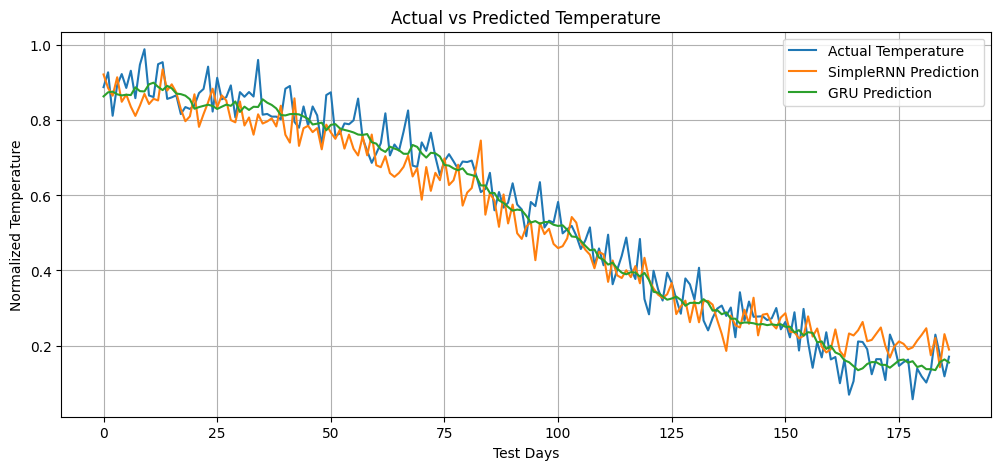

In [13]:
actual = np.concatenate([
    test_generator[i][1]
    for i in range(len(test_generator))
])

plt.figure(figsize=(12, 5))

plt.plot(actual, label='Actual Temperature')
plt.plot(rnn_predictions.flatten(), label='SimpleRNN Prediction')
plt.plot(gru_predictions.flatten(), label='GRU Prediction')

plt.title("Actual vs Predicted Temperature")
plt.xlabel("Test Days")
plt.ylabel("Normalized Temperature")
plt.legend()
plt.grid()

plt.show()

In [14]:
rnn_loss, rnn_mae = simple_rnn.evaluate(
    test_generator, verbose=0
)

gru_loss, gru_mae = gru_model.evaluate(
    test_generator, verbose=0
)

print("SimpleRNN Test MAE:", round(rnn_mae, 4))
print("GRU Test MAE:", round(gru_mae, 4))

SimpleRNN Test MAE: 0.0559
GRU Test MAE: 0.0391


       Model  Test Loss  Test MAE
0  SimpleRNN   0.004724  0.055928
1        GRU   0.002356  0.039066


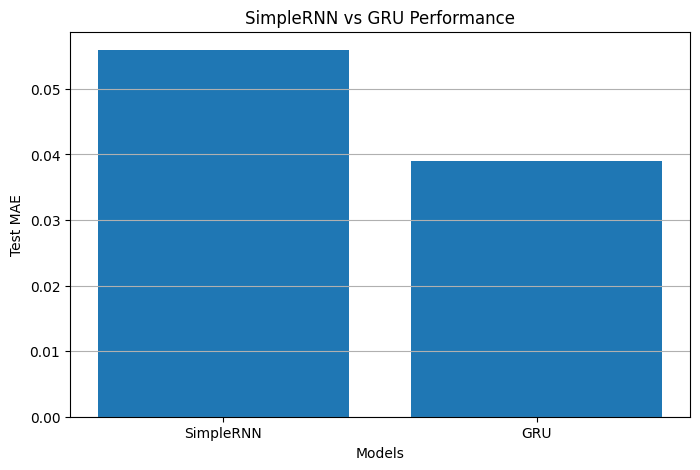

GRU performed better!


In [15]:
results = pd.DataFrame({
    'Model': ['SimpleRNN', 'GRU'],
    'Test Loss': [rnn_loss, gru_loss],
    'Test MAE': [rnn_mae, gru_mae]
})

print(results)

plt.figure(figsize=(8, 5))

plt.bar(results['Model'], results['Test MAE'])

plt.title("SimpleRNN vs GRU Performance")
plt.xlabel("Models")
plt.ylabel("Test MAE")

plt.grid(axis='y')
plt.show()

if gru_mae < rnn_mae:
    print("GRU performed better!")
else:
    print("SimpleRNN performed better!")